<a href="https://colab.research.google.com/github/KostantinDubnitskyi/Methodd/blob/main/%D0%9B%D0%A03_(%D0%94%D1%83%D0%B1%D0%BD%D0%B8%D1%86%D1%8C%D0%BA%D0%B8%D0%B9_4_8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)




## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [3]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])
df.head()



Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [4]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.
import kagglehub

path = kagglehub.dataset_download("prokshitha/home-value-insights")
print("Шлях до датасету:", path)

import os
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))
df.head()




100%|██████████| 26.4k/26.4k [00:00<00:00, 36.7MB/s]

Extracting files...
Шлях до датасету: /root/.cache/kagglehub/datasets/prokshitha/home-value-insights/versions/1


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [5]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.
print(df.shape)
df.head()




(1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [7]:
# Ваш код:
# Порахуйте кількість дублікатів.
print("Кількість дублікатів:", df.duplicated().sum())




Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [8]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.
print("Пропуски по стовпцях:")
print(df.isna().sum())




Пропуски по стовпцях:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [9]:
# Ваш код:
# Отримайте описову статистику датасету.
df.describe()




,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [10]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.
print(df["Neighborhood_Quality"].value_counts())




Neighborhood_Quality
10    123
5     109
2     105
7     102
6     101
4      99
8      97
1      91
9      88
3      85
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

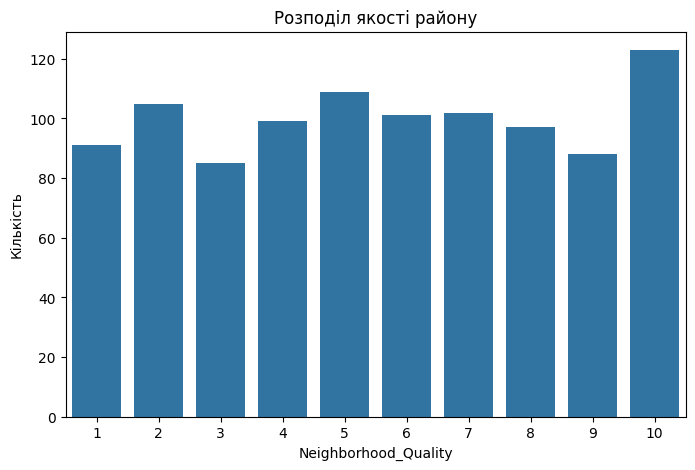

In [12]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
plt.figure(figsize=(8, 5))
sns.countplot(x="Neighborhood_Quality", data=df)
plt.title("Розподіл якості району")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість")
plt.show()




### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [13]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
print(df["Num_Bathrooms"].value_counts())




Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

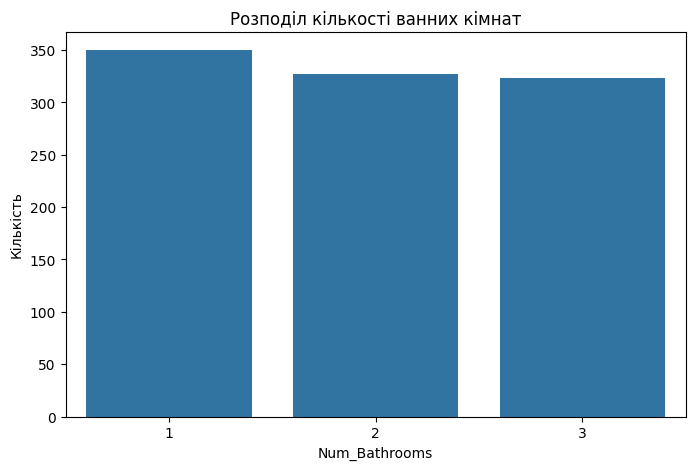

In [14]:
# Ваш код:
# Побудуйте відповідну діаграму.
plt.figure(figsize=(8, 5))
sns.countplot(x="Num_Bathrooms", data=df)
plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість")
plt.show()




### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

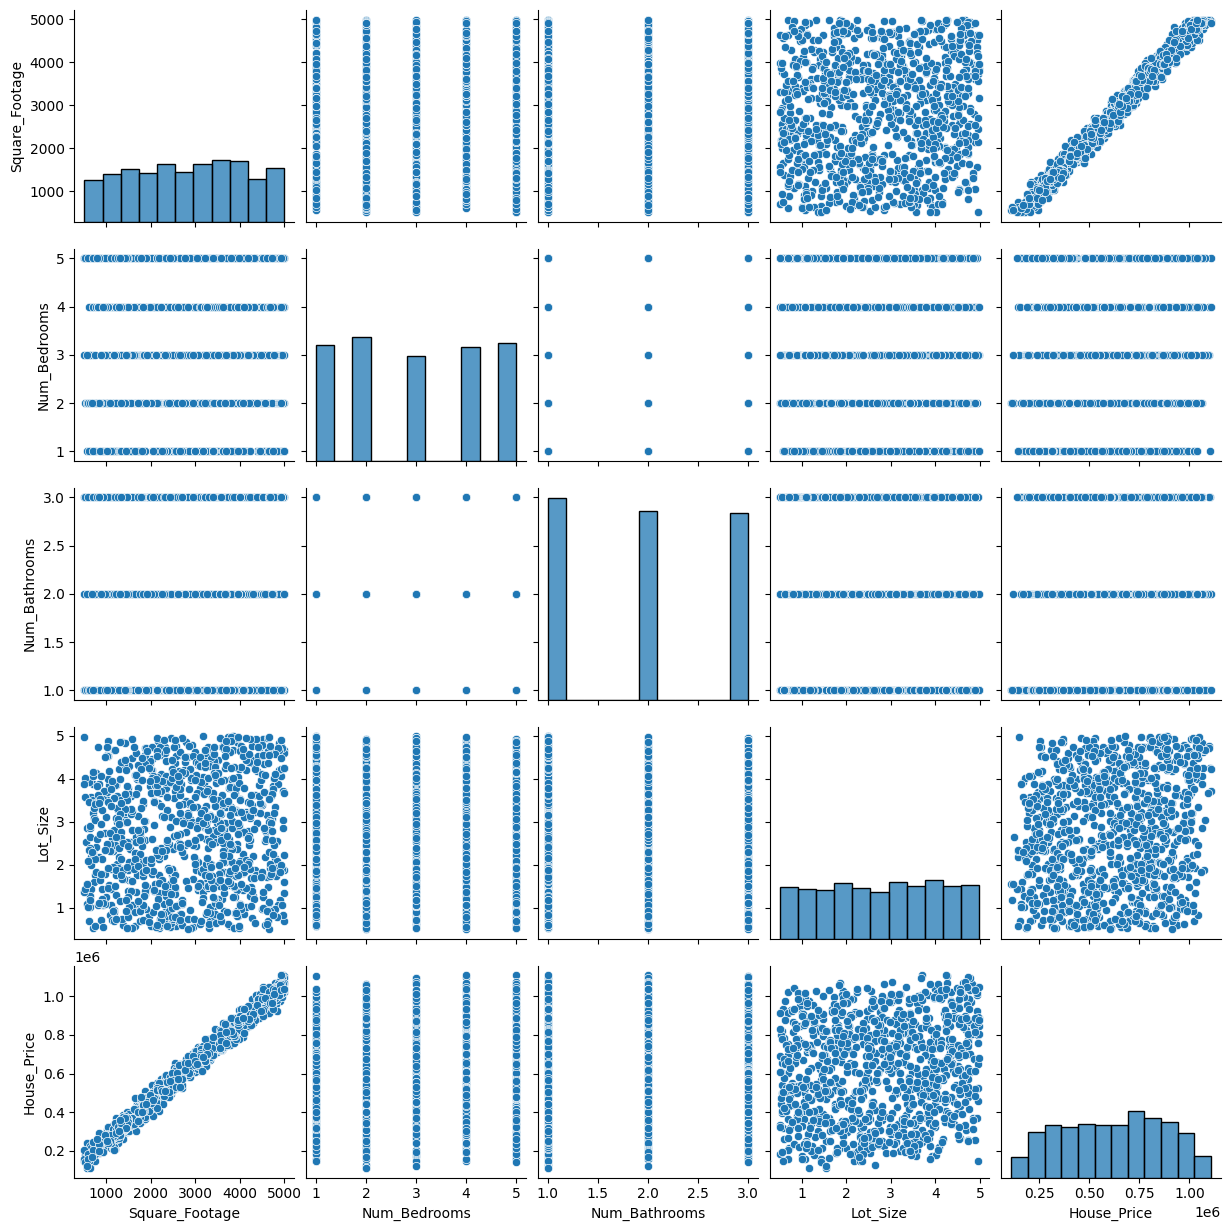

In [15]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.
sns.pairplot(df[["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "Lot_Size", "House_Price"]])
plt.show()




## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

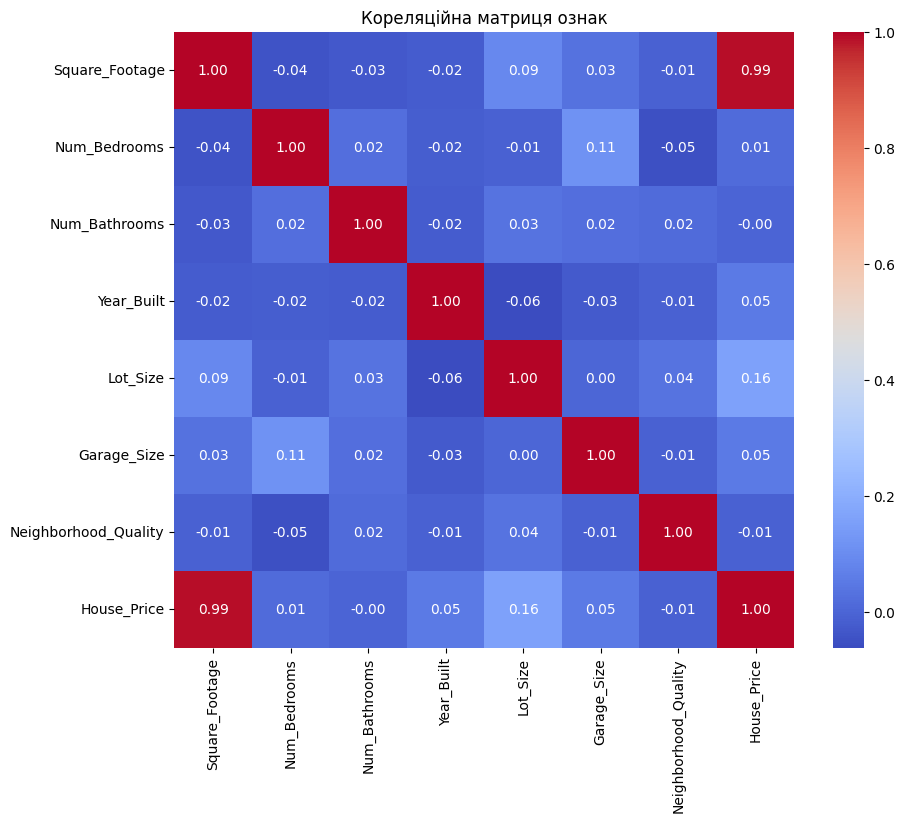

In [16]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Кореляційна матриця ознак")
plt.show()




### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [17]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.
price_correlation = df.corr(numeric_only=True)["House_Price"].sort_values(ascending=False)
print(price_correlation)




House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [18]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error




### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [19]:
# Ваш код:
# Створіть `X` та `y`.
X = df.drop(columns="House_Price")
y = df["House_Price"]

print("X.shape:", X.shape)
print("y.shape:", y.shape)




X.shape: (1000, 7)
y.shape: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [20]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)




Train: (800, 7)
Test : (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [21]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    "Linear Regression": Pipeline([
        ("scale", StandardScaler()),
        ("reg", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scale", StandardScaler()),
        ("reg", Ridge(alpha=1.0)),
    ]),
    "Lasso": Pipeline([
        ("scale", StandardScaler()),
        ("reg", Lasso(alpha=1.0, max_iter=20000)),
    ]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}




### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [22]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "model": name,
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
    })

results_table = pd.DataFrame(results).set_index("model")
results_table




,R2,MAE,MSE
model,,,
Linear Regression,0.998426,8174.583600,1.014348e+08
Ridge,0.998410,8241.586911,1.024810e+08
Lasso,0.998426,8174.748374,1.014366e+08
Random Forest,0.993886,16114.289644,3.941317e+08
Gradient Boosting,0.996510,12305.217615,2.249656e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

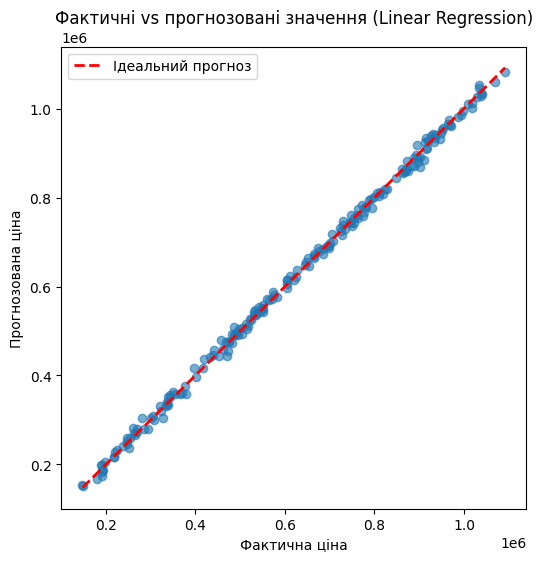

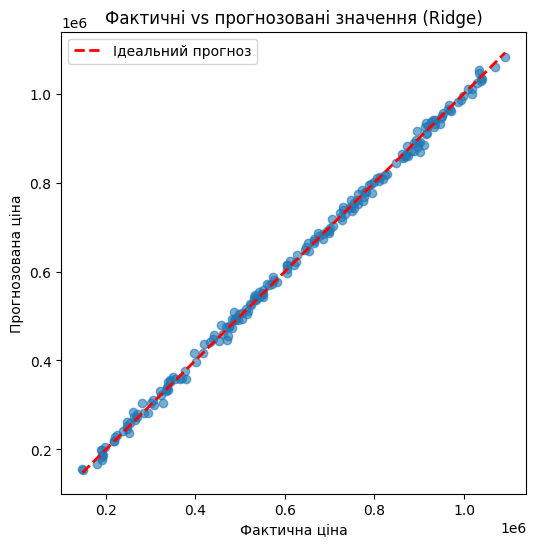

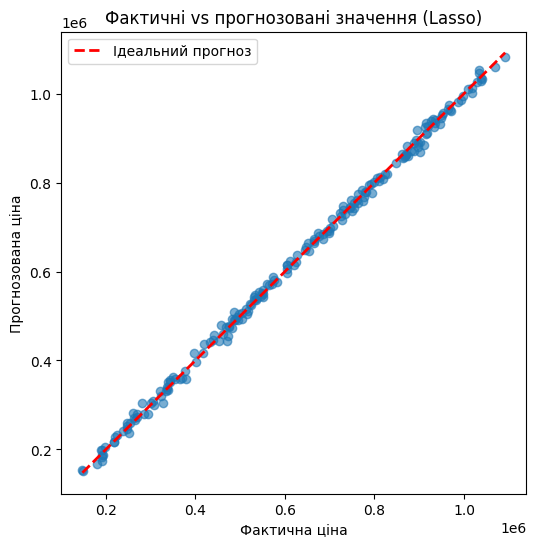

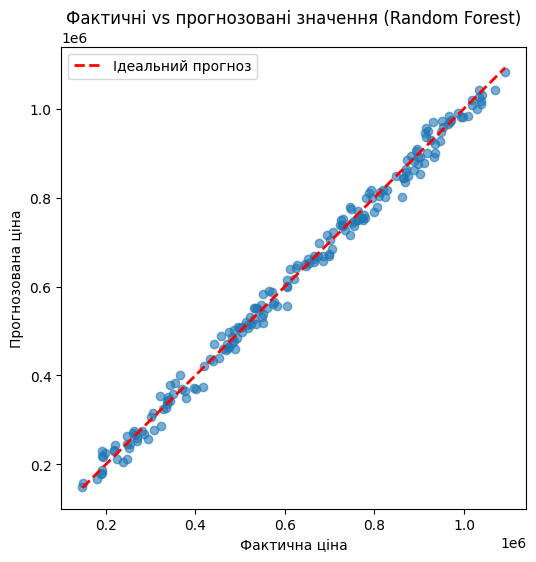

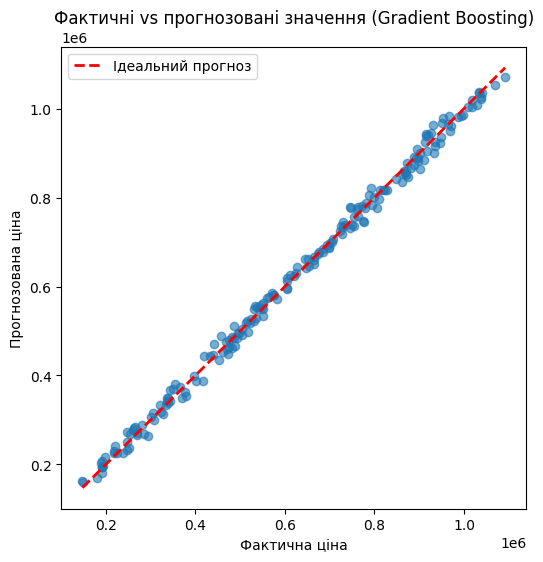

In [23]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.
for name, model in models.items():
    pred = model.predict(X_test)

    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred, alpha=0.6)
    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=2, label="Ідеальний прогноз"
    )
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(f"Фактичні vs прогнозовані значення ({name})")
    plt.legend()
    plt.show()




## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [26]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", None],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

print("Найкращі параметри:", rf_search.best_params_)
print("Найкращий CV R2:", rf_search.best_score_)




Найкращі параметри: {'max_depth': None, 'max_features': None, 'min_samples_split': 2, 'n_estimators': 300}
Найкращий CV R2: 0.991979290870707


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [27]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.
best_rf = RandomForestRegressor(**rf_search.best_params_, random_state=42)
best_rf.fit(X_train, y_train)
best_rf_pred = best_rf.predict(X_test)

best_rf_metrics = {
    "R2": r2_score(y_test, best_rf_pred),
    "MAE": mean_absolute_error(y_test, best_rf_pred),
    "MSE": mean_squared_error(y_test, best_rf_pred),
}

best_rf_metrics




{'R2': 0.9940298846807288, 'MAE': 15930.637875446102, 'MSE': 384826810.1531117}

### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [28]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
base_rf_pred = models["Random Forest"].predict(X_test)

base_rf_metrics = {
    "R2": r2_score(y_test, base_rf_pred),
    "MAE": mean_absolute_error(y_test, base_rf_pred),
    "MSE": mean_squared_error(y_test, base_rf_pred),
}

rf_comparison = pd.DataFrame({
    "Random Forest (базова)": base_rf_metrics,
    "Random Forest (оптимізована)": best_rf_metrics,
}).T

rf_comparison




,R2,MAE,MSE
Random Forest (базова),0.993886,16114.289644,3.941317e+08
Random Forest (оптимізована),0.994030,15930.637875,3.848268e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Після підбору гіперпараметрів через GridSearchCV якість моделі покращилась, але дуже незначно: R2 зріс з 0.993886 до 0.994030, MAE зменшився з 16114.29 до 15930.64, а MSE - з 3.941*10^8 до 3.848*10^8. Такий невеликий приріст свідчить про те, що параметри за замовчуванням уже були близькі до оптимальних для цього датасету.
Використовувати оптимізовану модель все ж таки доцільно, оскільки вона стабільно трохи краща за базову за всіма трьома метриками одночасно.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [29]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
linear_model = models["Linear Regression"]
linear_pred_final = linear_model.predict(X_test)

predictions_table = pd.DataFrame({
    "actual_price": y_test.values,
    "predicted_price": linear_pred_final,
})

predictions_table["error_%"] = (
    np.abs(predictions_table["actual_price"] - predictions_table["predicted_price"])
    / predictions_table["actual_price"] * 100
)

predictions_table.sample(10, random_state=42)




,actual_price,predicted_price,error_%
95,1.068538e+06,1.059729e+06,0.824406
15,1.943537e+05,1.878686e+05,3.336793
30,2.702306e+05,2.797158e+05,3.510031
158,9.860069e+05,9.819493e+05,0.411517
128,9.533397e+05,9.573829e+05,0.424111
115,9.145557e+05,9.097643e+05,0.523912
69,7.461677e+05,7.424691e+05,0.495678
170,6.467663e+05,6.544456e+05,1.187332
174,5.233231e+05,5.246054e+05,0.245045
45,1.008539e+06,1.011344e+06,0.278073


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

 У роботі було побудовано п'ять моделей регресії для прогнозування ціни нерухомості: Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting.

 Найкращі результати показали лінійні моделі - Linear Regression і Lasso практично зрівнялись за R2 (0.998426), з MAE близько 8174-8175 та MSE приблизно 1.014*10^8, що трохи краще навіть за Ridge (R2 = 0.998410).  Це свідчить про те, що залежність ціни від наявних ознак (площа, кількість кімнат тощо) у цьому датасеті, ймовірно, близька до лінійної.

 Підбір гіперпараметрів для Random Forest через GridSearchCV дав лише незначне покращення: R2 зріс з 0.993886 до 0.994030, MAE зменшився з 16114 до 15931, а MSE - з 3.941*10^8 до 3.848*10^8. Хоча оптимізована модель формально краща за базову, цей приріст надто малий.

 Точність прогнозів на тестовій вибірці - найкращі моделі (Linear Regression, Lasso) дають дуже високий R2 (понад 0.998), а середня абсолютна похибка (MAE) становить близько 8175, що є невеликим відхиленням.

 На якість прогнозування ціни нерухомості можуть впливати декілька факторів: повнота та якість вихідних даних, кількість ознак, а також сама залежності між ознаками і ціною - у цьому випадку вона виявилась переважно лінійною, що й пояснює перевагу простіших моделей над ансамблевими.